## Essential Libraries Import

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import random

## Data Loading

In [4]:
df = pd.read_csv(r'C:\Users\Hp\Desktop\Data Science Projects\Electricity Demand Forcasting - II\Data\Power_Demand_2021-2024.csv')

In [5]:
df.head()

,Unnamed: 0,datetime,Power demand,temp,dwpt,rhum,wdir,wspd,pres,year,month,day,hour,minute,moving_avg_3
0,0,2021-01-01 00:30:00,2014.00,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,30,NaN
1,1,2021-01-01 00:35:00,2005.63,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,35,NaN
2,2,2021-01-01 00:40:00,1977.60,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,40,1999.076667
3,3,2021-01-01 00:45:00,1976.44,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,45,1986.556667
4,4,2021-01-01 00:50:00,1954.37,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,50,1969.470000


## Data Cleaning and Transformation

In [6]:
df = df.rename(columns = {
    'datetime':'DateTime',
    'Power demand':'Power_Demand_MW',
    'temp':'Temp_cel',
    'dwpt':'Dew_Point_cel',
    'rhum':'Relative_Humidity_%',
    'wdir':'Wind_Drxn_deg',
    'wspd':'Wind_Spd_m/s',
    'pres':'Preassure_mbar'
}
)
df.columns = df.columns.str.title()

In [7]:
df['Datetime'] = pd.to_datetime(df['Datetime'])
df.set_index('Datetime', inplace = True)
df.head()

,Unnamed: 0,Power_Demand_Mw,Temp_Cel,Dew_Point_Cel,Relative_Humidity_%,Wind_Drxn_Deg,Wind_Spd_M/S,Preassure_Mbar,Year,Month,Day,Hour,Minute,Moving_Avg_3
Datetime,,,,,,,,,,,,,,
2021-01-01 00:30:00,0,2014.00,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,30,NaN
2021-01-01 00:35:00,1,2005.63,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,35,NaN
2021-01-01 00:40:00,2,1977.60,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,40,1999.076667
2021-01-01 00:45:00,3,1976.44,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,45,1986.556667
2021-01-01 00:50:00,4,1954.37,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,50,1969.470000


In [8]:
df.drop(columns = ['Unnamed: 0','Moving_Avg_3'], inplace = True)

In [9]:
df

,Power_Demand_Mw,Temp_Cel,Dew_Point_Cel,Relative_Humidity_%,Wind_Drxn_Deg,Wind_Spd_M/S,Preassure_Mbar,Year,Month,Day,Hour,Minute
Datetime,,,,,,,,,,,,
2021-01-01 00:30:00,2014.00,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,30
2021-01-01 00:35:00,2005.63,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,35
2021-01-01 00:40:00,1977.60,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,40
2021-01-01 00:45:00,1976.44,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,45
2021-01-01 00:50:00,1954.37,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,50
...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-12 00:10:00,2146.84,12.3,6.8,69.0,269.0,1.8,1019.4,2024,12,12,0,10
2024-12-12 00:15:00,2116.66,12.3,6.8,69.0,269.0,1.8,1019.4,2024,12,12,0,15
2024-12-12 00:20:00,2082.77,12.3,6.8,69.0,269.0,1.8,1019.4,2024,12,12,0,20


In [10]:
df.describe()

,Power_Demand_Mw,Temp_Cel,Dew_Point_Cel,Relative_Humidity_%,Wind_Drxn_Deg,Wind_Spd_M/S,Preassure_Mbar,Year,Month,Day,Hour,Minute
count,393440.000000,393440.000000,393440.000000,393440.000000,392900.000000,393440.000000,393440.000000,393440.000000,393440.000000,393440.000000,393440.000000,393440.000000
mean,3960.736469,25.527913,16.338046,63.435767,163.777081,7.854550,1008.932695,2022.487129,6.446991,15.745171,11.184371,27.354959
std,1300.473773,7.981563,7.377440,24.850663,116.888397,5.664314,6.902759,1.110587,3.412654,8.783091,6.797501,17.223877
min,1302.080000,4.000000,-8.600000,5.000000,0.000000,0.000000,989.600000,2021.000000,1.000000,1.000000,0.000000,0.000000
25%,3074.900000,20.000000,10.400000,44.000000,50.000000,5.400000,1003.000000,2021.000000,3.000000,8.000000,5.000000,10.000000
50%,3832.320000,27.000000,15.400000,67.000000,160.000000,7.600000,1009.000000,2022.000000,6.000000,16.000000,11.000000,25.000000
75%,4870.465000,31.000000,23.900000,84.000000,270.000000,11.200000,1015.000000,2023.000000,9.000000,23.000000,17.000000,40.000000
max,8631.530000,46.400000,30.300000,100.000000,360.000000,63.000000,1027.000000,2024.000000,12.000000,31.000000,23.000000,55.000000


In [11]:
df.isna().sum()

Power_Demand_Mw          0
Temp_Cel                 0
Dew_Point_Cel            0
Relative_Humidity_%      0
Wind_Drxn_Deg          540
Wind_Spd_M/S             0
Preassure_Mbar           0
Year                     0
Month                    0
Day                      0
Hour                     0
Minute                   0
dtype: int64

In [12]:
df['Missing_Wind_Drxn_Deg'] = df['Wind_Drxn_Deg'].isna().astype(int)

In [13]:
df['Wind_Drxn_Deg'] = df['Wind_Drxn_Deg'].ffill()

In [14]:
df.isna().sum()

Power_Demand_Mw          0
Temp_Cel                 0
Dew_Point_Cel            0
Relative_Humidity_%      0
Wind_Drxn_Deg            0
Wind_Spd_M/S             0
Preassure_Mbar           0
Year                     0
Month                    0
Day                      0
Hour                     0
Minute                   0
Missing_Wind_Drxn_Deg    0
dtype: int64

In [15]:
df.head()

,Power_Demand_Mw,Temp_Cel,Dew_Point_Cel,Relative_Humidity_%,Wind_Drxn_Deg,Wind_Spd_M/S,Preassure_Mbar,Year,Month,Day,Hour,Minute,Missing_Wind_Drxn_Deg
Datetime,,,,,,,,,,,,,
2021-01-01 00:30:00,2014.00,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,30,0
2021-01-01 00:35:00,2005.63,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,35,0
2021-01-01 00:40:00,1977.60,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,40,0
2021-01-01 00:45:00,1976.44,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,45,0
2021-01-01 00:50:00,1954.37,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,50,0


## Feature Engineering

In [16]:
df['Day_Name'] = df.index.day_name()
df['Day_of_Week'] = df.index.dayofweek + 1
df['Is_Weekend'] = (df.index.dayofweek >= 5).astype(int)
df

,Power_Demand_Mw,Temp_Cel,Dew_Point_Cel,Relative_Humidity_%,Wind_Drxn_Deg,Wind_Spd_M/S,Preassure_Mbar,Year,Month,Day,Hour,Minute,Missing_Wind_Drxn_Deg,Day_Name,Day_of_Week,Is_Weekend
Datetime,,,,,,,,,,,,,,,,
2021-01-01 00:30:00,2014.00,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,30,0,Friday,5,0
2021-01-01 00:35:00,2005.63,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,35,0,Friday,5,0
2021-01-01 00:40:00,1977.60,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,40,0,Friday,5,0
2021-01-01 00:45:00,1976.44,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,45,0,Friday,5,0
2021-01-01 00:50:00,1954.37,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,50,0,Friday,5,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-12 00:10:00,2146.84,12.3,6.8,69.0,269.0,1.8,1019.4,2024,12,12,0,10,0,Thursday,4,0
2024-12-12 00:15:00,2116.66,12.3,6.8,69.0,269.0,1.8,1019.4,2024,12,12,0,15,0,Thursday,4,0
2024-12-12 00:20:00,2082.77,12.3,6.8,69.0,269.0,1.8,1019.4,2024,12,12,0,20,0,Thursday,4,0


In [17]:
%pip install holidays

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: C:\Users\Hp\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [18]:
import holidays

In [19]:
holiday_calendar = holidays.country_holidays('IN', years = range(df.index.year.min(), df.index.year.max() + 1))
df["Is_Holiday"] = df.index.normalize().isin(holiday_calendar).astype(int)
df

,Power_Demand_Mw,Temp_Cel,Dew_Point_Cel,Relative_Humidity_%,Wind_Drxn_Deg,Wind_Spd_M/S,Preassure_Mbar,Year,Month,Day,Hour,Minute,Missing_Wind_Drxn_Deg,Day_Name,Day_of_Week,Is_Weekend,Is_Holiday
Datetime,,,,,,,,,,,,,,,,,
2021-01-01 00:30:00,2014.00,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,30,0,Friday,5,0,0
2021-01-01 00:35:00,2005.63,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,35,0,Friday,5,0,0
2021-01-01 00:40:00,1977.60,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,40,0,Friday,5,0,0
2021-01-01 00:45:00,1976.44,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,45,0,Friday,5,0,0
2021-01-01 00:50:00,1954.37,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,50,0,Friday,5,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-12 00:10:00,2146.84,12.3,6.8,69.0,269.0,1.8,1019.4,2024,12,12,0,10,0,Thursday,4,0,0
2024-12-12 00:15:00,2116.66,12.3,6.8,69.0,269.0,1.8,1019.4,2024,12,12,0,15,0,Thursday,4,0,0
2024-12-12 00:20:00,2082.77,12.3,6.8,69.0,269.0,1.8,1019.4,2024,12,12,0,20,0,Thursday,4,0,0


In [20]:
df['Demand_Lag_5min'] = df['Power_Demand_Mw'].shift(freq = '5min')
df['Demand_Lag_1hr'] = df['Power_Demand_Mw'].shift(freq = '1h')
df['Demand_Lag_1day'] = df['Power_Demand_Mw'].shift(freq = '1D')
df['Demand_Lag_1week'] = df['Power_Demand_Mw'].shift(freq = '7D')
df['Demand_mean_last_hour'] = (df['Power_Demand_Mw'].shift(freq="5min").rolling("1h", min_periods=12).mean())
df = df.dropna()
df

,Power_Demand_Mw,Temp_Cel,Dew_Point_Cel,Relative_Humidity_%,Wind_Drxn_Deg,Wind_Spd_M/S,Preassure_Mbar,Year,Month,Day,...,Missing_Wind_Drxn_Deg,Day_Name,Day_of_Week,Is_Weekend,Is_Holiday,Demand_Lag_5min,Demand_Lag_1hr,Demand_Lag_1day,Demand_Lag_1week,Demand_mean_last_hour
Datetime,,,,,,,,,,,,,,,,,,,,,
2021-01-08 01:00:00,4540.94,13.0,12.1,94.0,0.0,0.0,1014.0,2021,1,8,...,0,Friday,5,0,0,4589.17,4818.90,6433.78,1907.98,4697.857500
2021-01-08 01:05:00,4531.97,13.0,12.1,94.0,0.0,0.0,1014.0,2021,1,8,...,0,Friday,5,0,0,4540.94,4790.19,6424.96,1878.74,4674.694167
2021-01-08 01:10:00,4492.71,13.0,12.1,94.0,0.0,0.0,1014.0,2021,1,8,...,0,Friday,5,0,0,4531.97,4770.34,6402.61,1859.68,4653.175833
2021-01-08 01:15:00,4467.78,13.0,12.1,94.0,0.0,0.0,1014.0,2021,1,8,...,0,Friday,5,0,0,4492.71,4746.19,6372.71,1836.56,4630.040000
2021-01-08 01:20:00,4456.23,13.0,12.1,94.0,0.0,0.0,1014.0,2021,1,8,...,0,Friday,5,0,0,4467.78,4733.47,6356.84,1820.73,4606.839167
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-11 22:05:00,3206.83,13.1,6.7,65.0,263.0,3.7,1019.0,2024,12,11,...,0,Wednesday,3,0,0,3246.70,3348.17,3790.84,4125.33,3305.935000
2024-12-11 22:10:00,3195.14,13.1,6.7,65.0,263.0,3.7,1019.0,2024,12,11,...,0,Wednesday,3,0,0,3206.83,3311.41,3812.28,4167.85,3294.156667
2024-12-11 22:15:00,3181.27,13.1,6.7,65.0,263.0,3.7,1019.0,2024,12,11,...,0,Wednesday,3,0,0,3195.14,3297.00,3824.71,4167.21,3284.467500


In [21]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 347745 entries, 2021-01-08 01:00:00 to 2024-12-11 22:25:00
Data columns (total 22 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Power_Demand_Mw        347745 non-null  float64
 1   Temp_Cel               347745 non-null  float64
 2   Dew_Point_Cel          347745 non-null  float64
 3   Relative_Humidity_%    347745 non-null  float64
 4   Wind_Drxn_Deg          347745 non-null  float64
 5   Wind_Spd_M/S           347745 non-null  float64
 6   Preassure_Mbar         347745 non-null  float64
 7   Year                   347745 non-null  int64  
 8   Month                  347745 non-null  int64  
 9   Day                    347745 non-null  int64  
 10  Hour                   347745 non-null  int64  
 11  Minute                 347745 non-null  int64  
 12  Missing_Wind_Drxn_Deg  347745 non-null  int64  
 13  Day_Name               347745 non-null  str    
 14  Day_of_Week  

In [22]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["Day_Name"] = pd.Categorical(df["Day_Name"], categories = day_order, ordered = True)

## Exploratory Data Analysis and Visualisation

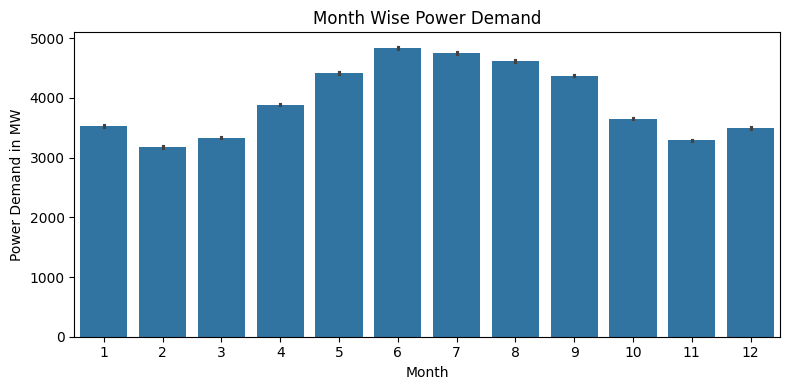

In [23]:
plt.figure(figsize = (8,4))
sns.barplot(
    data = df,
    x = 'Month',
    y = 'Power_Demand_Mw'
)
plt.title('Month Wise Power Demand')
plt.xlabel('Month')
plt.ylabel('Power Demand in MW')
plt.tight_layout()
plt.show()

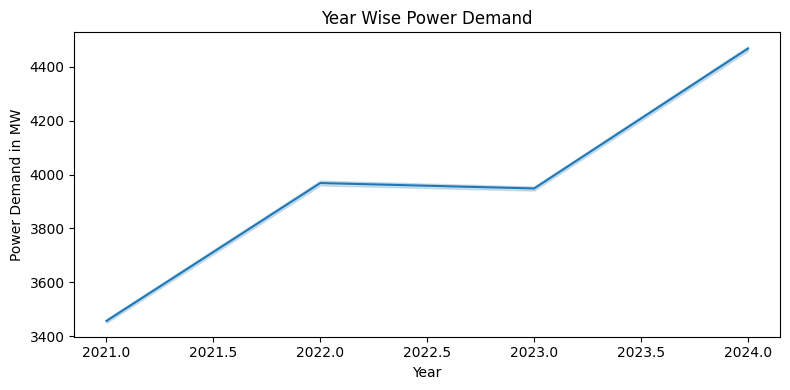

In [24]:
plt.figure(figsize = (8,4))
sns.lineplot(
    data = df,
    x = 'Year',
    y = 'Power_Demand_Mw'
)
plt.title('Year Wise Power Demand')
plt.xlabel('Year')
plt.ylabel('Power Demand in MW')
plt.tight_layout()
plt.show()

In [25]:
df.index = pd.to_datetime(df.index)
df = df.sort_index()
daily_df = (df['Power_Demand_Mw'].resample('D').mean().rename('Power Demand').rename_axis('Date').reset_index())

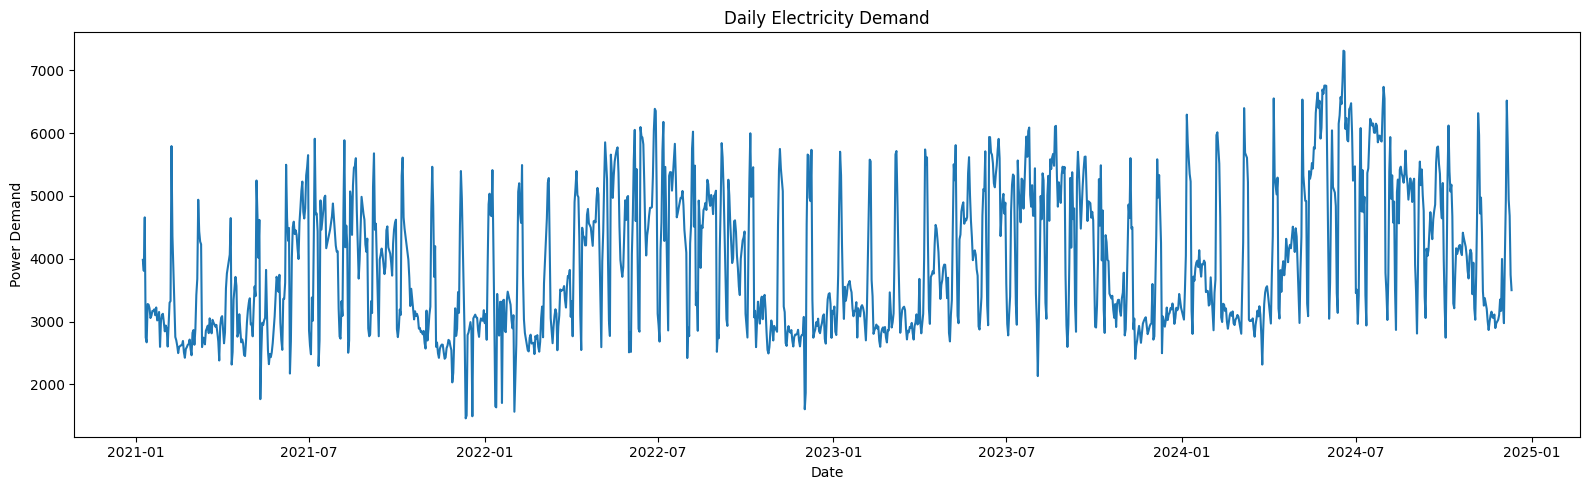

In [26]:
plt.figure(figsize=(16, 5))
sns.lineplot(
    data = daily_df,
    x = 'Date',
    y = 'Power Demand'
)
plt.title('Daily Electricity Demand')
plt.xlabel('Date')
plt.ylabel('Power Demand')
plt.tight_layout()
plt.show()

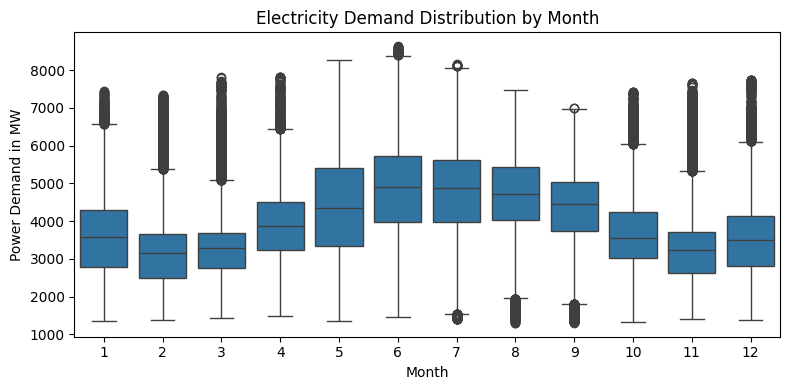

In [27]:
plt.figure(figsize = (8,4))
sns.boxplot(
    data = df,
    x = 'Month',
    y = 'Power_Demand_Mw'
)
plt.title('Electricity Demand Distribution by Month')
plt.xlabel('Month')
plt.ylabel('Power Demand in MW')
plt.tight_layout()
plt.show()

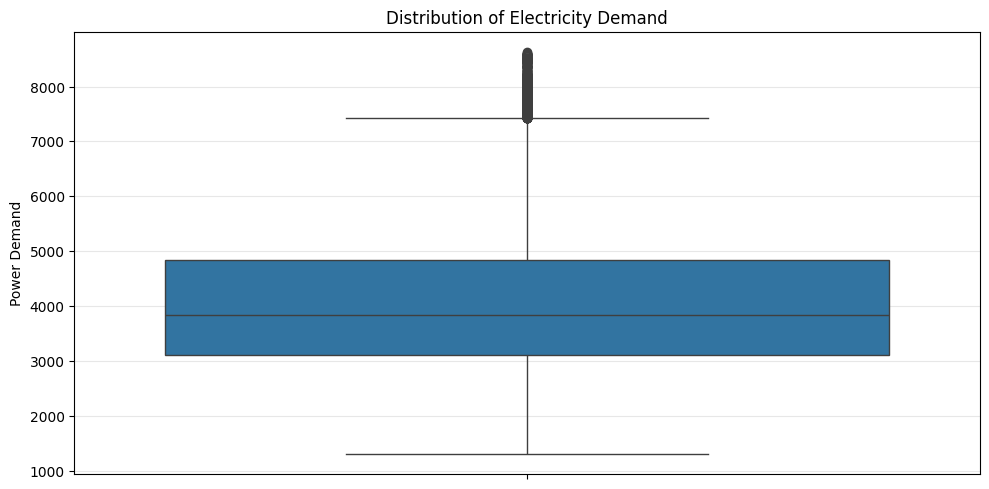

In [28]:
plt.figure(figsize=(10,5))
sns.boxplot(y = df['Power_Demand_Mw'])
plt.title('Distribution of Electricity Demand')
plt.ylabel('Power Demand')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Text(0.5, 0, 'Temperature in deg_cel')

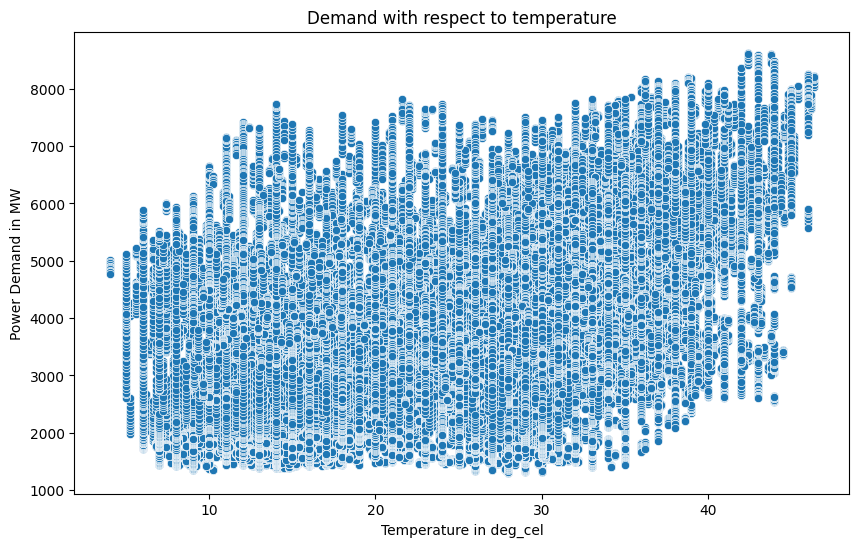

In [29]:
plt.figure(figsize = (10,6))
sns.scatterplot(data = df, x = 'Temp_Cel', y = 'Power_Demand_Mw')
plt.title('Demand with respect to temperature')
plt.ylabel('Power Demand in MW')
plt.xlabel('Temperature in deg_cel')

Text(0.5, 0, 'Dew Point in deg_cel')

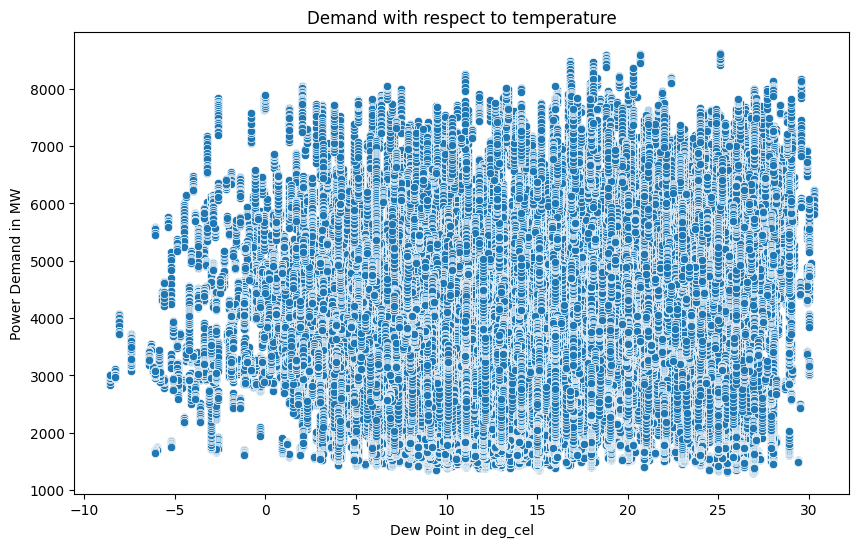

In [30]:
plt.figure(figsize = (10,6))
sns.scatterplot(data = df, x = 'Dew_Point_Cel', y = 'Power_Demand_Mw')
plt.title('Demand with respect to temperature')
plt.ylabel('Power Demand in MW')
plt.xlabel('Dew Point in deg_cel')

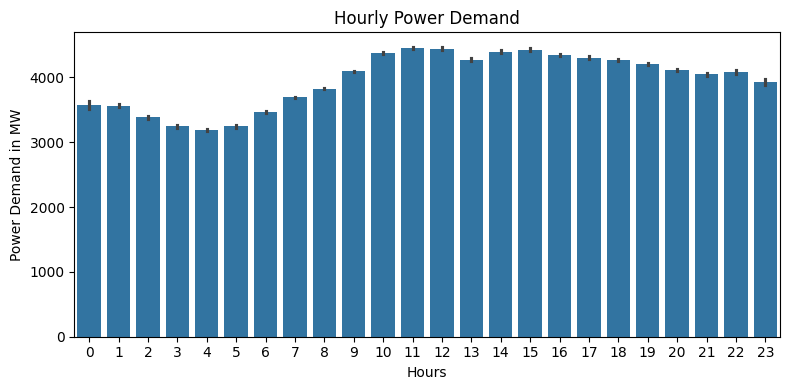

In [31]:
plt.figure(figsize = (8,4))
sns.barplot(
    data = df,
    x = 'Hour',
    y = 'Power_Demand_Mw'
)
plt.title('Hourly Power Demand')
plt.xlabel('Hours')
plt.ylabel('Power Demand in MW')
plt.tight_layout()
plt.show()

In [32]:
directions = np.array(["N", "NE", "E", "SE", "S", "SW", "W", "NW"])
direction_index = (((df["Wind_Drxn_Deg"].astype(float) % 360 + 22.5) // 45).astype(int) % 8)
df["Wind_Drxn"] = directions[direction_index.to_numpy()]
wind_drxn_column = df.pop("Wind_Drxn")
df.insert(4, "Wind_Drxn", wind_drxn_column)
df.drop(columns = ['Wind_Drxn_Deg'], inplace = True)
df

,Power_Demand_Mw,Temp_Cel,Dew_Point_Cel,Relative_Humidity_%,Wind_Drxn,Wind_Spd_M/S,Preassure_Mbar,Year,Month,Day,...,Missing_Wind_Drxn_Deg,Day_Name,Day_of_Week,Is_Weekend,Is_Holiday,Demand_Lag_5min,Demand_Lag_1hr,Demand_Lag_1day,Demand_Lag_1week,Demand_mean_last_hour
Datetime,,,,,,,,,,,,,,,,,,,,,
2021-01-08 01:00:00,4540.94,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,...,0,Friday,5,0,0,4589.17,4818.90,6433.78,1907.98,4697.857500
2021-01-08 01:05:00,4531.97,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,...,0,Friday,5,0,0,4540.94,4790.19,6424.96,1878.74,4674.694167
2021-01-08 01:10:00,4492.71,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,...,0,Friday,5,0,0,4531.97,4770.34,6402.61,1859.68,4653.175833
2021-01-08 01:15:00,4467.78,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,...,0,Friday,5,0,0,4492.71,4746.19,6372.71,1836.56,4630.040000
2021-01-08 01:20:00,4456.23,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,...,0,Friday,5,0,0,4467.78,4733.47,6356.84,1820.73,4606.839167
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-11 22:05:00,3206.83,13.1,6.7,65.0,W,3.7,1019.0,2024,12,11,...,0,Wednesday,3,0,0,3246.70,3348.17,3790.84,4125.33,3305.935000
2024-12-11 22:10:00,3195.14,13.1,6.7,65.0,W,3.7,1019.0,2024,12,11,...,0,Wednesday,3,0,0,3206.83,3311.41,3812.28,4167.85,3294.156667
2024-12-11 22:15:00,3181.27,13.1,6.7,65.0,W,3.7,1019.0,2024,12,11,...,0,Wednesday,3,0,0,3195.14,3297.00,3824.71,4167.21,3284.467500


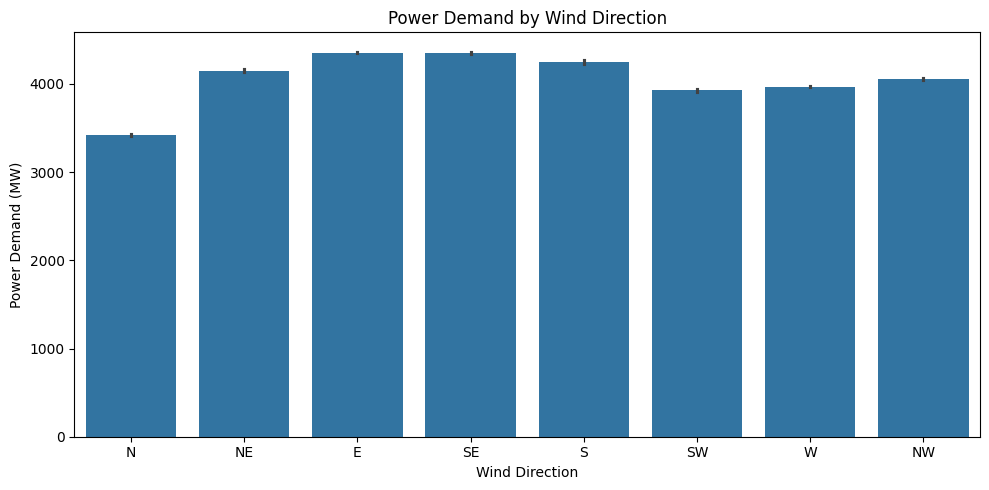

In [33]:
wind_order = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df,
    x="Wind_Drxn",
    y="Power_Demand_Mw",
    order=wind_order,
    estimator="mean"
)
plt.title("Power Demand by Wind Direction")
plt.xlabel("Wind Direction")
plt.ylabel("Power Demand (MW)")
plt.tight_layout()
plt.show()

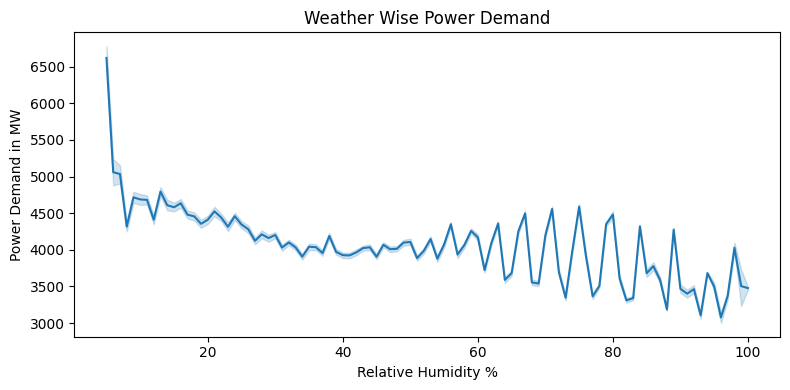

In [34]:
plt.figure(figsize = (8,4))
sns.lineplot(
    data = df,
    x = 'Relative_Humidity_%',
    y = 'Power_Demand_Mw'
)
plt.title('Weather Wise Power Demand')
plt.xlabel('Relative Humidity %')
plt.ylabel('Power Demand in MW')
plt.tight_layout()
plt.show()

<Axes: >

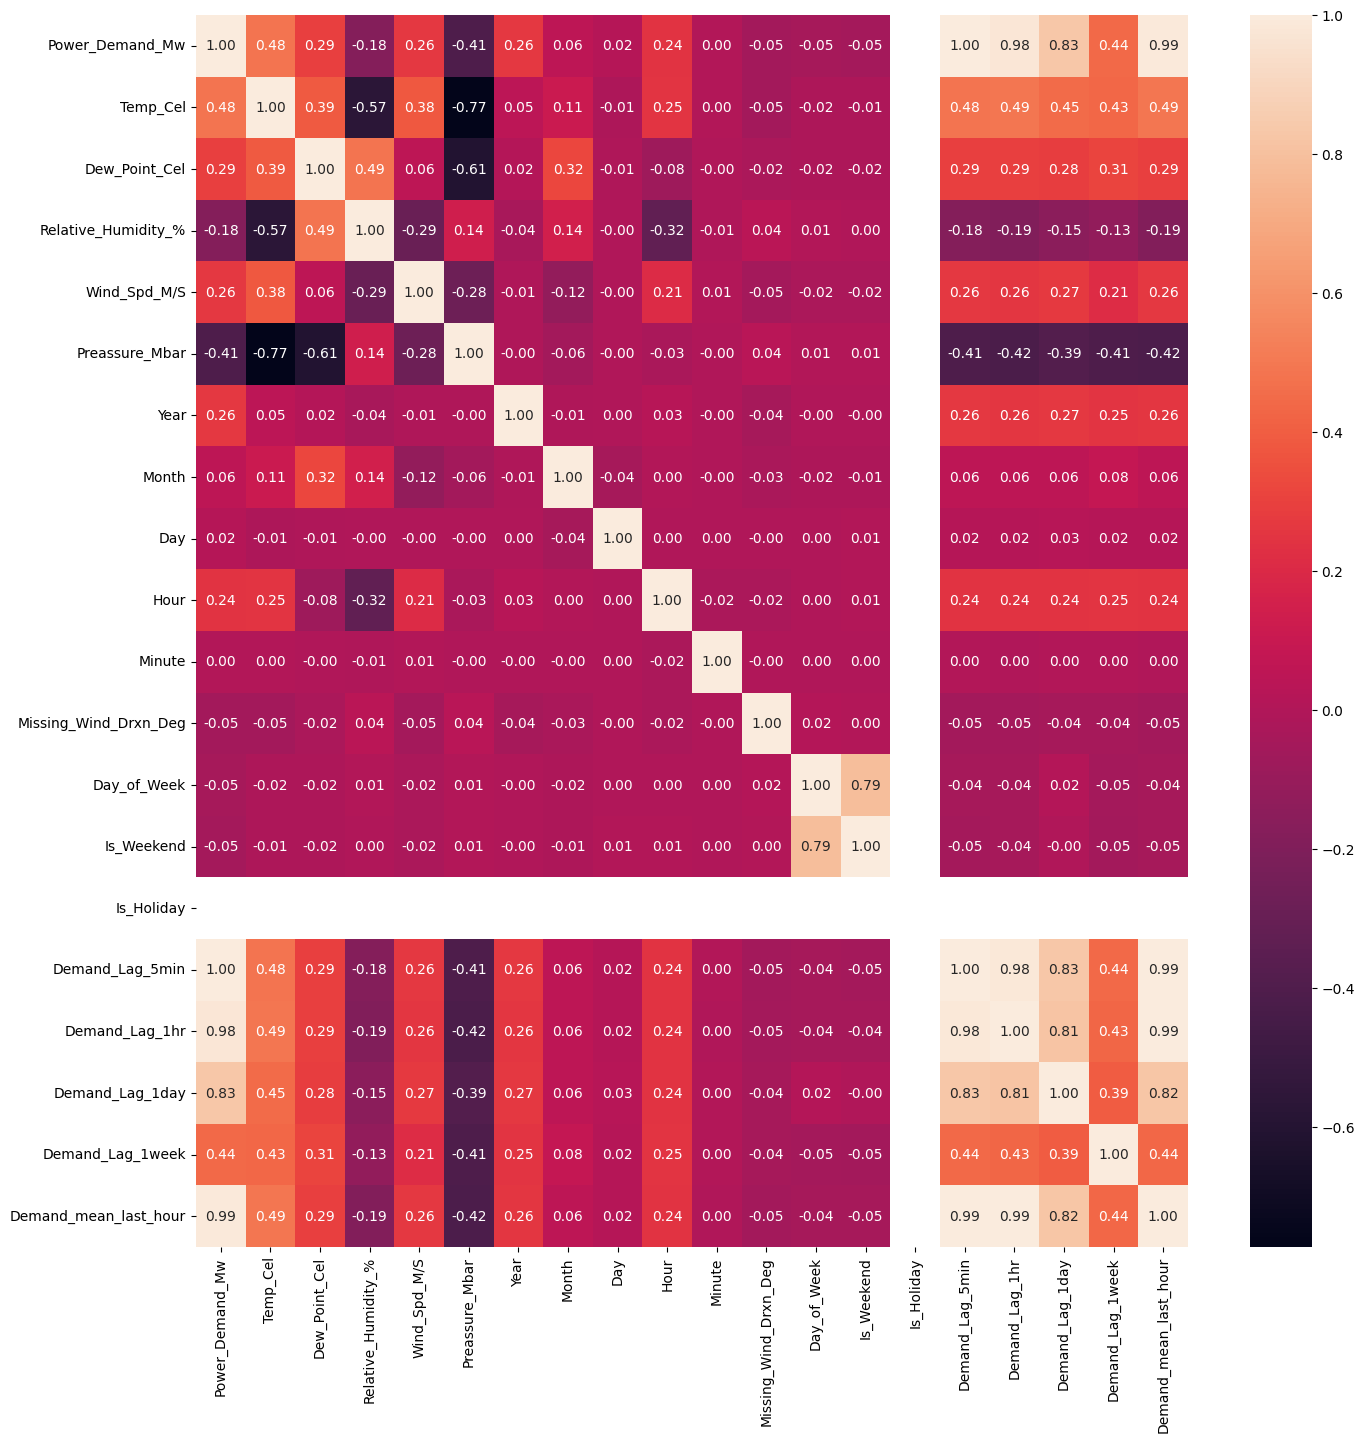

In [35]:
plt.figure(figsize = (16,16))
numeric_data = df.select_dtypes(include = 'number')
corr_metrics = numeric_data.corr()
sns.heatmap(corr_metrics, annot = True, fmt = '.2f')

In [36]:
df

,Power_Demand_Mw,Temp_Cel,Dew_Point_Cel,Relative_Humidity_%,Wind_Drxn,Wind_Spd_M/S,Preassure_Mbar,Year,Month,Day,...,Missing_Wind_Drxn_Deg,Day_Name,Day_of_Week,Is_Weekend,Is_Holiday,Demand_Lag_5min,Demand_Lag_1hr,Demand_Lag_1day,Demand_Lag_1week,Demand_mean_last_hour
Datetime,,,,,,,,,,,,,,,,,,,,,
2021-01-08 01:00:00,4540.94,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,...,0,Friday,5,0,0,4589.17,4818.90,6433.78,1907.98,4697.857500
2021-01-08 01:05:00,4531.97,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,...,0,Friday,5,0,0,4540.94,4790.19,6424.96,1878.74,4674.694167
2021-01-08 01:10:00,4492.71,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,...,0,Friday,5,0,0,4531.97,4770.34,6402.61,1859.68,4653.175833
2021-01-08 01:15:00,4467.78,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,...,0,Friday,5,0,0,4492.71,4746.19,6372.71,1836.56,4630.040000
2021-01-08 01:20:00,4456.23,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,...,0,Friday,5,0,0,4467.78,4733.47,6356.84,1820.73,4606.839167
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-11 22:05:00,3206.83,13.1,6.7,65.0,W,3.7,1019.0,2024,12,11,...,0,Wednesday,3,0,0,3246.70,3348.17,3790.84,4125.33,3305.935000
2024-12-11 22:10:00,3195.14,13.1,6.7,65.0,W,3.7,1019.0,2024,12,11,...,0,Wednesday,3,0,0,3206.83,3311.41,3812.28,4167.85,3294.156667
2024-12-11 22:15:00,3181.27,13.1,6.7,65.0,W,3.7,1019.0,2024,12,11,...,0,Wednesday,3,0,0,3195.14,3297.00,3824.71,4167.21,3284.467500


## Feature-Target Split : Splitting Data on the Basis of Dependent and Independent variables

In [37]:
Y = df['Power_Demand_Mw']
Y

Datetime
2021-01-08 01:00:00    4540.94
2021-01-08 01:05:00    4531.97
2021-01-08 01:10:00    4492.71
2021-01-08 01:15:00    4467.78
2021-01-08 01:20:00    4456.23
                        ...   
2024-12-11 22:05:00    3206.83
2024-12-11 22:10:00    3195.14
2024-12-11 22:15:00    3181.27
2024-12-11 22:20:00    3159.38
2024-12-11 22:25:00    3152.87
Name: Power_Demand_Mw, Length: 347745, dtype: float64

In [38]:
X = df.drop(columns = ['Power_Demand_Mw'])
X

,Temp_Cel,Dew_Point_Cel,Relative_Humidity_%,Wind_Drxn,Wind_Spd_M/S,Preassure_Mbar,Year,Month,Day,Hour,...,Missing_Wind_Drxn_Deg,Day_Name,Day_of_Week,Is_Weekend,Is_Holiday,Demand_Lag_5min,Demand_Lag_1hr,Demand_Lag_1day,Demand_Lag_1week,Demand_mean_last_hour
Datetime,,,,,,,,,,,,,,,,,,,,,
2021-01-08 01:00:00,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,1,...,0,Friday,5,0,0,4589.17,4818.90,6433.78,1907.98,4697.857500
2021-01-08 01:05:00,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,1,...,0,Friday,5,0,0,4540.94,4790.19,6424.96,1878.74,4674.694167
2021-01-08 01:10:00,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,1,...,0,Friday,5,0,0,4531.97,4770.34,6402.61,1859.68,4653.175833
2021-01-08 01:15:00,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,1,...,0,Friday,5,0,0,4492.71,4746.19,6372.71,1836.56,4630.040000
2021-01-08 01:20:00,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,1,...,0,Friday,5,0,0,4467.78,4733.47,6356.84,1820.73,4606.839167
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-11 22:05:00,13.1,6.7,65.0,W,3.7,1019.0,2024,12,11,22,...,0,Wednesday,3,0,0,3246.70,3348.17,3790.84,4125.33,3305.935000
2024-12-11 22:10:00,13.1,6.7,65.0,W,3.7,1019.0,2024,12,11,22,...,0,Wednesday,3,0,0,3206.83,3311.41,3812.28,4167.85,3294.156667
2024-12-11 22:15:00,13.1,6.7,65.0,W,3.7,1019.0,2024,12,11,22,...,0,Wednesday,3,0,0,3195.14,3297.00,3824.71,4167.21,3284.467500


## Train-Validation-Test Split  

In [39]:
X_train = X.loc[ :'2022-12-31']
X_train

,Temp_Cel,Dew_Point_Cel,Relative_Humidity_%,Wind_Drxn,Wind_Spd_M/S,Preassure_Mbar,Year,Month,Day,Hour,...,Missing_Wind_Drxn_Deg,Day_Name,Day_of_Week,Is_Weekend,Is_Holiday,Demand_Lag_5min,Demand_Lag_1hr,Demand_Lag_1day,Demand_Lag_1week,Demand_mean_last_hour
Datetime,,,,,,,,,,,,,,,,,,,,,
2021-01-08 01:00:00,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,1,...,0,Friday,5,0,0,4589.17,4818.90,6433.78,1907.98,4697.857500
2021-01-08 01:05:00,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,1,...,0,Friday,5,0,0,4540.94,4790.19,6424.96,1878.74,4674.694167
2021-01-08 01:10:00,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,1,...,0,Friday,5,0,0,4531.97,4770.34,6402.61,1859.68,4653.175833
2021-01-08 01:15:00,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,1,...,0,Friday,5,0,0,4492.71,4746.19,6372.71,1836.56,4630.040000
2021-01-08 01:20:00,13.0,12.1,94.0,N,0.0,1014.0,2021,1,8,1,...,0,Friday,5,0,0,4467.78,4733.47,6356.84,1820.73,4606.839167
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-12-31 23:20:00,12.0,11.1,94.0,N,0.0,1020.0,2022,12,31,23,...,0,Saturday,6,1,0,2623.18,2921.39,2506.92,2352.37,2783.374167
2022-12-31 23:25:00,12.0,11.1,94.0,N,0.0,1020.0,2022,12,31,23,...,0,Saturday,6,1,0,2600.98,2909.70,2465.07,2310.77,2756.673333
2022-12-31 23:30:00,11.2,9.9,92.0,W,5.4,1021.2,2022,12,31,23,...,0,Saturday,6,1,0,2581.91,2876.93,2420.03,2285.97,2729.357500


In [40]:
Y_train = Y.loc[ :'2022-12-31']
Y_train

Datetime
2021-01-08 01:00:00    4540.94
2021-01-08 01:05:00    4531.97
2021-01-08 01:10:00    4492.71
2021-01-08 01:15:00    4467.78
2021-01-08 01:20:00    4456.23
                        ...   
2022-12-31 23:20:00    2600.98
2022-12-31 23:25:00    2581.91
2022-12-31 23:30:00    2548.52
2022-12-31 23:35:00    2508.53
2022-12-31 23:40:00    2477.98
Name: Power_Demand_Mw, Length: 168334, dtype: float64

In [41]:
X_valid = X.loc["2023-01-01":"2023-12-31"]
X_valid

,Temp_Cel,Dew_Point_Cel,Relative_Humidity_%,Wind_Drxn,Wind_Spd_M/S,Preassure_Mbar,Year,Month,Day,Hour,...,Missing_Wind_Drxn_Deg,Day_Name,Day_of_Week,Is_Weekend,Is_Holiday,Demand_Lag_5min,Demand_Lag_1hr,Demand_Lag_1day,Demand_Lag_1week,Demand_mean_last_hour
Datetime,,,,,,,,,,,,,,,,,,,,,
2023-01-01 01:30:00,10.0,9.1,94.0,W,5.4,1020.0,2023,1,1,1,...,0,Sunday,7,1,0,1994.30,2196.99,1828.43,1753.35,2089.480000
2023-01-01 01:35:00,10.0,9.1,94.0,W,5.4,1020.0,2023,1,1,1,...,0,Sunday,7,1,0,1980.15,2162.20,1819.96,1737.52,2071.410000
2023-01-01 01:40:00,10.0,9.1,94.0,W,5.4,1020.0,2023,1,1,1,...,0,Sunday,7,1,0,1973.29,2146.48,1796.61,1727.65,2055.667500
2023-01-01 01:45:00,10.0,9.1,94.0,W,5.4,1020.0,2023,1,1,1,...,0,Sunday,7,1,0,1968.11,2141.46,1809.72,1720.70,2040.803333
2023-01-01 01:50:00,10.0,9.1,94.0,W,5.4,1020.0,2023,1,1,1,...,0,Sunday,7,1,0,1952.33,2123.61,1789.63,1696.81,2025.042500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-12-31 21:20:00,13.1,9.7,80.0,NE,7.6,1019.5,2023,12,31,21,...,0,Sunday,7,1,0,3108.88,3475.24,3147.74,2821.17,3260.537500
2023-12-31 21:25:00,13.1,9.7,80.0,NE,7.6,1019.5,2023,12,31,21,...,0,Sunday,7,1,0,3098.88,3459.11,3138.62,2793.21,3229.174167
2023-12-31 22:30:00,12.0,9.0,82.0,NE,5.4,1019.0,2023,12,31,22,...,0,Sunday,7,1,0,2800.17,3087.06,2751.91,2486.28,2945.235000


In [42]:
Y_valid = Y.loc["2023-01-01":"2023-12-31"]
Y_valid

Datetime
2023-01-01 01:30:00    1980.15
2023-01-01 01:35:00    1973.29
2023-01-01 01:40:00    1968.11
2023-01-01 01:45:00    1952.33
2023-01-01 01:50:00    1928.51
                        ...   
2023-12-31 21:20:00    3098.88
2023-12-31 21:25:00    3068.88
2023-12-31 22:30:00    2770.55
2023-12-31 22:35:00    2770.55
2023-12-31 22:40:00    2770.55
Name: Power_Demand_Mw, Length: 95366, dtype: float64

In [43]:
X_test = X.loc['2024-01-01':]
X_test

,Temp_Cel,Dew_Point_Cel,Relative_Humidity_%,Wind_Drxn,Wind_Spd_M/S,Preassure_Mbar,Year,Month,Day,Hour,...,Missing_Wind_Drxn_Deg,Day_Name,Day_of_Week,Is_Weekend,Is_Holiday,Demand_Lag_5min,Demand_Lag_1hr,Demand_Lag_1day,Demand_Lag_1week,Demand_mean_last_hour
Datetime,,,,,,,,,,,,,,,,,,,,,
2024-01-03 00:00:00,9.4,8.2,92.0,N,7.6,1019.3,2024,1,3,0,...,0,Wednesday,3,0,0,2483.49,3016.37,2535.71,2104.60,2739.081667
2024-01-03 00:05:00,9.4,8.2,92.0,N,7.6,1019.3,2024,1,3,0,...,0,Wednesday,3,0,0,2197.09,2932.11,2473.16,2060.78,2670.808333
2024-01-03 00:10:00,9.4,8.2,92.0,N,7.6,1019.3,2024,1,3,0,...,0,Wednesday,3,0,0,2162.02,2926.48,2456.83,2025.63,2606.634167
2024-01-03 00:15:00,9.4,8.2,92.0,N,7.6,1019.3,2024,1,3,0,...,0,Wednesday,3,0,0,2140.29,2852.22,2410.87,2012.77,2541.118333
2024-01-03 00:20:00,9.4,8.2,92.0,N,7.6,1019.3,2024,1,3,0,...,0,Wednesday,3,0,0,2111.18,2823.33,2378.55,1994.70,2479.365000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-11 22:05:00,13.1,6.7,65.0,W,3.7,1019.0,2024,12,11,22,...,0,Wednesday,3,0,0,3246.70,3348.17,3790.84,4125.33,3305.935000
2024-12-11 22:10:00,13.1,6.7,65.0,W,3.7,1019.0,2024,12,11,22,...,0,Wednesday,3,0,0,3206.83,3311.41,3812.28,4167.85,3294.156667
2024-12-11 22:15:00,13.1,6.7,65.0,W,3.7,1019.0,2024,12,11,22,...,0,Wednesday,3,0,0,3195.14,3297.00,3824.71,4167.21,3284.467500


In [44]:
Y_test = Y.loc['2024-01-01':]
Y_test

Datetime
2024-01-03 00:00:00    2197.09
2024-01-03 00:05:00    2162.02
2024-01-03 00:10:00    2140.29
2024-01-03 00:15:00    2111.18
2024-01-03 00:20:00    2097.82
                        ...   
2024-12-11 22:05:00    3206.83
2024-12-11 22:10:00    3195.14
2024-12-11 22:15:00    3181.27
2024-12-11 22:20:00    3159.38
2024-12-11 22:25:00    3152.87
Name: Power_Demand_Mw, Length: 84045, dtype: float64

## Baseline Evaluation Using Pre-Definded Metrics

In [45]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [46]:
baseline_prediction = X_valid['Demand_Lag_1day']

In [47]:
baseline_mae = mean_absolute_error(Y_valid, baseline_prediction)
baseline_rmse = mean_squared_error(Y_valid, baseline_prediction) ** 0.5
baseline_r2 = r2_score(Y_valid, baseline_prediction)
print("Baseline MAE:", baseline_mae,'MW')
print("Baseline RMSE:", baseline_rmse,'MW')
print("Baseline R²:", baseline_r2)

Baseline MAE: 463.3760212234969 MW
Baseline RMSE: 709.5041854838114 MW
Baseline R²: 0.6482990033662174


## Feature Separation

In [48]:
categorical_features = X.select_dtypes(include = ['object','string','category']).columns.tolist()
numeric_features = X.columns.difference(categorical_features).tolist()
print('Categorical Features : ', categorical_features)
print('Numeric Features : ', numeric_features)

Categorical Features :  ['Wind_Drxn', 'Day_Name']
Numeric Features :  ['Day', 'Day_of_Week', 'Demand_Lag_1day', 'Demand_Lag_1hr', 'Demand_Lag_1week', 'Demand_Lag_5min', 'Demand_mean_last_hour', 'Dew_Point_Cel', 'Hour', 'Is_Holiday', 'Is_Weekend', 'Minute', 'Missing_Wind_Drxn_Deg', 'Month', 'Preassure_Mbar', 'Relative_Humidity_%', 'Temp_Cel', 'Wind_Spd_M/S', 'Year']


## Data Preprocessing Pipeline

In [49]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [50]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

## Model Development and Validation : Competing Models, Measured Results

## Linear Regression

In [51]:
from sklearn.linear_model import LinearRegression
linear_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model',LinearRegression())
])
linear_model.fit(X_train,Y_train)
linear_valid_prediction = linear_model.predict(X_valid)

In [52]:
linear_mae = mean_absolute_error(Y_valid, linear_valid_prediction)
linear_rmse = mean_squared_error(Y_valid, linear_valid_prediction) ** 0.5
linear_r2 = r2_score(Y_valid, linear_valid_prediction)
print("Linear Regression MAE:", linear_mae, 'MW')
print("Linear Regression RMSE:", linear_rmse, 'MW')
print("Linear Regression R²:", linear_r2)

Linear Regression MAE: 23.477149274924344 MW
Linear Regression RMSE: 37.84040518078967 MW
Linear Regression R²: 0.9989995964331934


In [53]:
baseline_5min_prediction = X_valid['Demand_Lag_5min']
baseline_5min_mae = mean_absolute_error(Y_valid, baseline_5min_prediction)
baseline_5min_rmse = mean_squared_error(Y_valid, baseline_5min_prediction) ** 0.5
baseline_5min_r2 = r2_score(Y_valid, baseline_5min_prediction)
print("5-Minute Baseline MAE:", baseline_5min_mae, 'MW')
print("5-Minute Baseline RMSE:", baseline_5min_rmse, 'MW')
print("5-Minute Baseline R²:", baseline_5min_r2)

5-Minute Baseline MAE: 27.33890128557347 MW
5-Minute Baseline RMSE: 41.254371992501476 MW
5-Minute Baseline R²: 0.9988109403657769


## Random Forest Regression

In [54]:
from sklearn.ensemble import RandomForestRegressor

In [55]:
random_forest_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(n_estimators = 20, random_state = 42, n_jobs = -1))
])
random_forest_model.fit(X_train, Y_train)
rf_valid_prediction = random_forest_model.predict(X_valid) 

In [56]:
rf_mae = mean_absolute_error(Y_valid, rf_valid_prediction)
rf_rmse = mean_squared_error(Y_valid, rf_valid_prediction) ** 0.5
rf_r2 = r2_score(Y_valid, rf_valid_prediction)

print("Random Forest MAE:", rf_mae, "MW")
print("Random Forest RMSE:", rf_rmse, "MW")
print("Random Forest R²:", rf_r2)

Random Forest MAE: 24.60651651531992 MW
Random Forest RMSE: 40.64345562971846 MW
Random Forest R²: 0.9988458960506033


## XGBoost Regression

In [58]:
%pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: C:\Users\Hp\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [59]:
from xgboost import XGBRegressor
xgb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(
        n_estimators = 200,
        random_state = 42,
        n_jobs = -1
    ))
])
xgb_model.fit(X_train, Y_train)
xgb_valid_prediction = xgb_model.predict(X_valid)

xgb_mae = mean_absolute_error(Y_valid, xgb_valid_prediction)
xgb_rmse = mean_squared_error(Y_valid, xgb_valid_prediction) ** 0.5
xgb_r2 = r2_score(Y_valid, xgb_valid_prediction)

print("XGBoost MAE:", xgb_mae, "MW")
print("XGBoost RMSE:", xgb_rmse, "MW")
print("XGBoost R²:", xgb_r2)

XGBoost MAE: 26.84279531138997 MW
XGBoost RMSE: 58.12916369456572 MW
XGBoost R²: 0.9976392400704277


## Visualizing the Best-Performing Forecast Model

In [60]:
validation_plot = pd.DataFrame({
    "Actual Demand": Y_valid,
    "Linear Regression Prediction": linear_valid_prediction
})
plot_df = validation_plot.loc[
    "2023-01-01":"2023-01-07 23:55"
].copy()

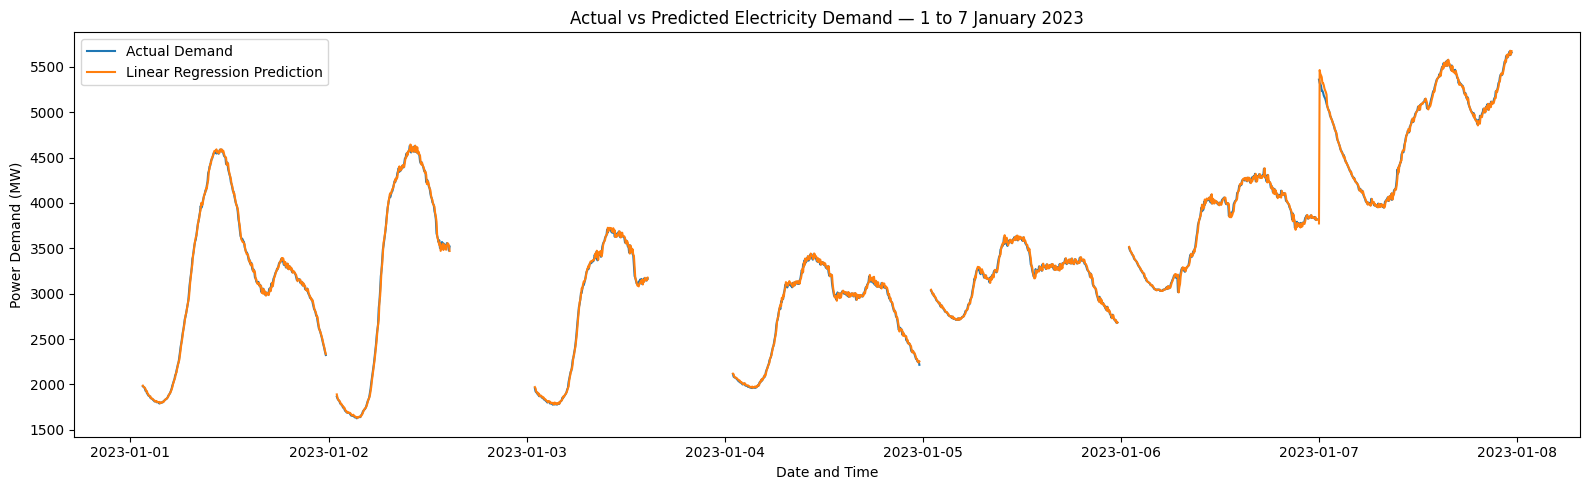

In [61]:
plot_df["segment"] = (
    plot_df.index.to_series()
    .diff()
    .gt(pd.Timedelta(minutes=5))
    .cumsum()
)
plt.figure(figsize=(16, 5))
for index, (_, part) in enumerate(plot_df.groupby("segment")):
    plt.plot(
        part.index,
        part["Actual Demand"],
        color="tab:blue",
        label="Actual Demand" if index == 0 else None
    )
    plt.plot(
        part.index,
        part["Linear Regression Prediction"],
        color="tab:orange",
        label="Linear Regression Prediction" if index == 0 else None
)
plt.title("Actual vs Predicted Electricity Demand — 1 to 7 January 2023")
plt.xlabel("Date and Time")
plt.ylabel("Power Demand (MW)")
plt.legend()
plt.tight_layout()
plt.show()

In [62]:
expected_interval = pd.Timedelta(minutes = 5)
time_gaps = df.index.to_series().diff()
large_gaps = time_gaps[time_gaps > expected_interval]
print(large_gaps)

Datetime
2021-01-09 01:00:00   0 days 02:05:00
2021-01-10 01:00:00   0 days 01:10:00
2021-01-11 01:00:00   0 days 01:10:00
2021-01-12 01:00:00   0 days 01:10:00
2021-01-13 01:00:00   0 days 01:15:00
                            ...      
2024-12-07 00:00:00   0 days 00:20:00
2024-12-08 01:00:00   0 days 01:15:00
2024-12-09 00:00:00   0 days 01:20:00
2024-12-10 01:00:00   0 days 02:25:00
2024-12-11 01:00:00   0 days 02:35:00
Name: Datetime, Length: 1316, dtype: timedelta64[us]


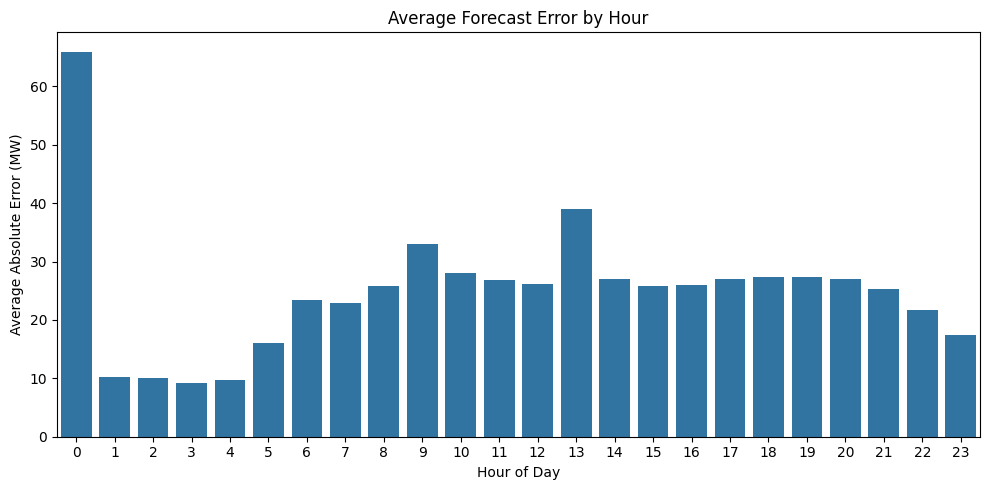

In [63]:
validation_errors = X_valid[["Hour"]].copy()
validation_errors["Actual"] = Y_valid
validation_errors["Predicted"] = linear_valid_prediction
validation_errors["Absolute_Error"] = (
    validation_errors["Actual"] - validation_errors["Predicted"]
).abs()
hourly_error = (
    validation_errors.groupby("Hour")["Absolute_Error"]
    .mean()
    .reset_index()
)
plt.figure(figsize=(10, 5))
sns.barplot(
    data=hourly_error,
    x="Hour",
    y="Absolute_Error"
)
plt.title("Average Forecast Error by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Absolute Error (MW)")
plt.tight_layout()
plt.show()

## The Final Forecast: Test-Set Performance and Visualization

In [64]:
from sklearn.base import clone

In [65]:
X_final_train = pd.concat([X_train, X_valid]).sort_index()
Y_final_train = pd.concat([Y_train, Y_valid]).sort_index()
final_linear_model = clone(linear_model)
final_linear_model.fit(X_final_train, Y_final_train)
final_test_prediction = final_linear_model.predict(X_test)

In [66]:
final_test_mae = mean_absolute_error( Y_test, final_test_prediction)
final_test_rmse = mean_squared_error(Y_test, final_test_prediction) ** 0.5
final_test_r2 = r2_score(Y_test, final_test_prediction)
print("Final Test MAE:", final_test_mae, "MW")
print("Final Test RMSE:", final_test_rmse, "MW")
print("Final Test R²:", final_test_r2)

Final Test MAE: 24.592599470136392 MW
Final Test RMSE: 41.87162183523456 MW
Final Test R²: 0.9990572278425038


In [67]:
test_baseline_prediction = X_test["Demand_Lag_5min"]
test_baseline_mae = mean_absolute_error(Y_test, test_baseline_prediction)
test_baseline_rmse = mean_squared_error(Y_test, test_baseline_prediction) ** 0.5
print("Test Baseline MAE:", test_baseline_mae, "MW")
print("Test Baseline RMSE:", test_baseline_rmse, "MW")

Test Baseline MAE: 29.091664941400442 MW
Test Baseline RMSE: 45.41684452526575 MW


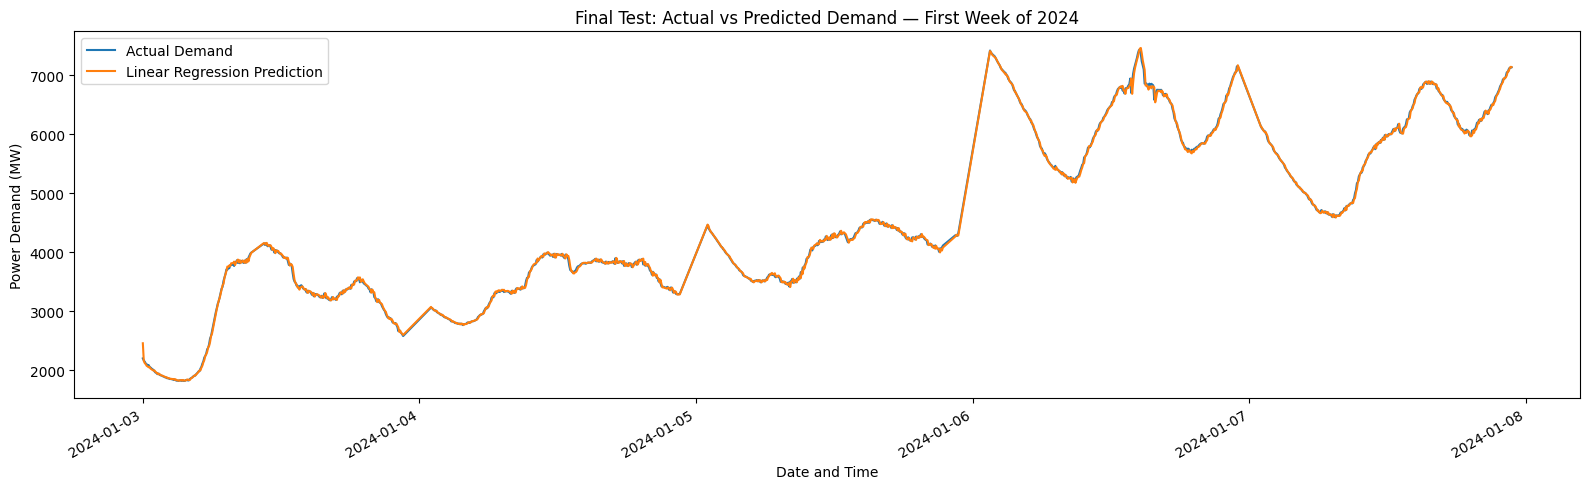

In [68]:
test_plot = pd.DataFrame({
    "Actual Demand": Y_test,
    "Linear Regression Prediction": final_test_prediction
})
test_week = test_plot.loc["2024-01-01":"2024-01-07 23:55"]
test_week.plot(figsize=(16, 5), title="Final Test: Actual vs Predicted Demand — First Week of 2024")
plt.xlabel("Date and Time")
plt.ylabel("Power Demand (MW)")
plt.tight_layout()
plt.show()

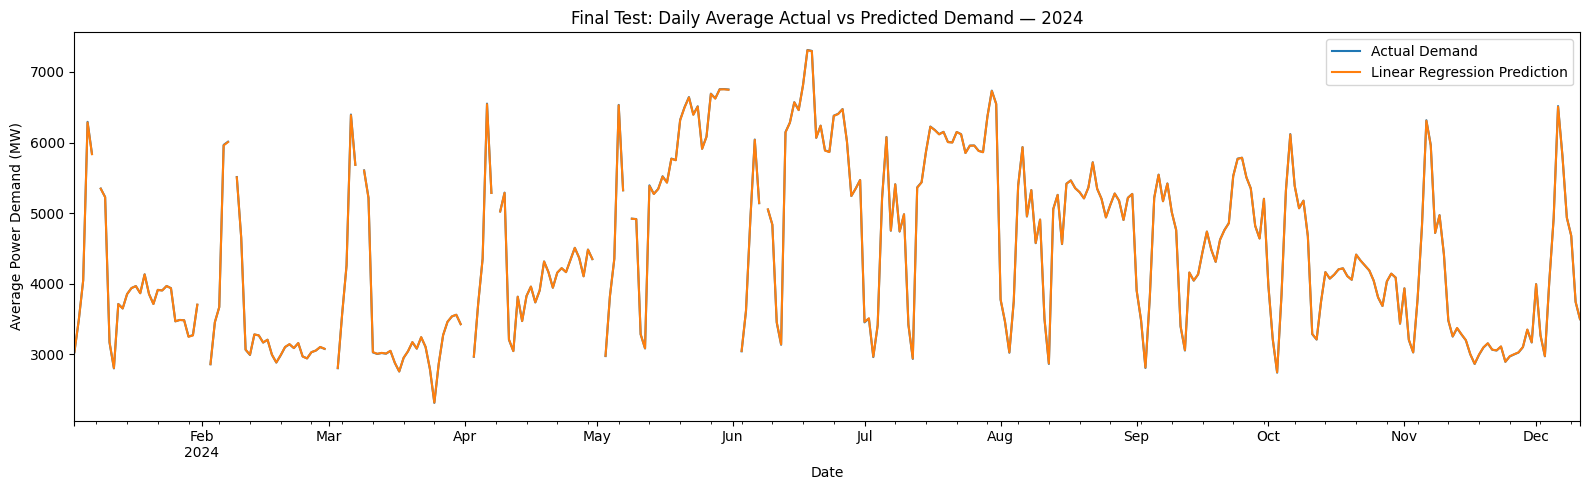

In [69]:
annual_test_plot = test_plot.resample("D").mean()
annual_test_plot.plot(
    figsize=(16, 5),
    title="Final Test: Daily Average Actual vs Predicted Demand — 2024"
)
plt.xlabel("Date")
plt.ylabel("Average Power Demand (MW)")
plt.tight_layout()
plt.show()

## Model Persistence and Reload Verification

In [76]:
import joblib
joblib.dump(linear_model, "Electricity Demand Forcasting Model.pkl")

['Electricity Demand Forcasting Model.pkl']

In [77]:
loaded_model = joblib.load("Electricity Demand Forcasting Model.pkl")

## Final Conclusion

This project developed a five-minute-ahead electricity-demand forecasting model using weather, calendar, and historical-demand features.

Linear Regression was selected after comparison with a persistence baseline, Random Forest, and XGBoost.

On the unseen 2024 test data, the model achieved:

- MAE: 24.59 MW
- RMSE: 41.87 MW
- R²: 0.9991

The model improved MAE by approximately 15.5% compared with the five-minute persistence baseline.

The model is appropriate for short-term operational forecasting when recent demand readings are available. Missing timestamp intervals remain a data-quality limitation and should be handled with a fallback rule in production.